# Case Study- Kidney Disease

In [1]:
# Importing the necessary libraries
import numpy as np # numerical calculations
import pandas as pd # data manipulation and data analysis
import matplotlib.pyplot as plt # data visualisations
import seaborn as sns # advance data visualisations

import warnings
warnings.filterwarnings("ignore")

In [2]:
# Importing the dataset
df = pd.read_csv('kidney_disease.csv')

# sample data
df.head()

,id,age,bp,sg,al,su,rbc,pc,pcc,ba,...,pcv,wc,rc,htn,dm,cad,appet,pe,ane,classification
0,0,48.0,80.0,1.020,1.0,0.0,NaN,normal,notpresent,notpresent,...,44,7800,5.2,yes,yes,no,good,no,no,ckd
1,1,7.0,50.0,1.020,4.0,0.0,NaN,normal,notpresent,notpresent,...,38,6000,NaN,no,no,no,good,no,no,ckd
2,2,62.0,80.0,1.010,2.0,3.0,normal,normal,notpresent,notpresent,...,31,7500,NaN,no,yes,no,poor,no,yes,ckd
3,3,48.0,70.0,1.005,4.0,0.0,normal,abnormal,present,notpresent,...,32,6700,3.9,yes,no,no,poor,yes,yes,ckd
4,4,51.0,80.0,1.010,2.0,0.0,normal,normal,notpresent,notpresent,...,35,7300,4.6,no,no,no,good,no,no,ckd


- Numerical Features
1. id → Unique patient ID
2. age → Age of patient
3. bp → Blood pressure (mm/Hg)
4. sg → Specific gravity of urine (1.005–1.025)
5. al → Albumin (protein in urine, 0–5 scale)
6. su → Sugar level in urine (0–5 scale)
7. bgr → Blood glucose random
8. bu → Blood urea
9. sc → Serum creatinine
10. sod → Sodium level
11. pot → Potassium level
12. hemo → Hemoglobin
- Categorical (Object) Features
1. rbc → Red blood cells (normal / abnormal)
2. pc → Pus cells (normal / abnormal)
3. pcc → Pus cell clumps (present / notpresent)
4. ba → Bacteria (present / notpresent)
5. pcv → Packed cell volume
6. wc → White blood cell count
7. rc → Red blood cell count
8. htn → Hypertension (yes / no)
9. dm → Diabetes mellitus (yes / no)
10. cad → Coronary artery disease (yes / no)
11. appet → Appetite (good / poor)
12. pe → Pedal edema (yes / no)
13. ane → Anemia (yes / no)
14. Target Variable
15. ckd → Chronic Kidney Disease
16. notckd → No kidney disease


In [3]:
# shape of the dataset
df.shape

(400, 26)

In [4]:
# column names
df.columns

Index(['id', 'age', 'bp', 'sg', 'al', 'su', 'rbc', 'pc', 'pcc', 'ba', 'bgr',
       'bu', 'sc', 'sod', 'pot', 'hemo', 'pcv', 'wc', 'rc', 'htn', 'dm', 'cad',
       'appet', 'pe', 'ane', 'classification'],
      dtype='object')

In [5]:
# duplicated values in the dataset
df.duplicated().sum()   # treating duplicates:- df.drop_duplicates()

np.int64(0)

In [7]:
# checking for null values
df.isnull().sum()

id                  0
age                 9
bp                 12
sg                 47
al                 46
su                 49
rbc               152
pc                 65
pcc                 4
ba                  4
bgr                44
bu                 19
sc                 17
sod                87
pot                88
hemo               52
pcv                70
wc                105
rc                130
htn                 2
dm                  2
cad                 2
appet               1
pe                  1
ane                 1
classification      0
dtype: int64

In [8]:
# checking for null values
df.isnull().sum().sum()

np.int64(1009)

In [9]:
# checking for missing values in '%' format
df.isnull().sum()/len(df)*100

id                 0.00
age                2.25
bp                 3.00
sg                11.75
al                11.50
su                12.25
rbc               38.00
pc                16.25
pcc                1.00
ba                 1.00
bgr               11.00
bu                 4.75
sc                 4.25
sod               21.75
pot               22.00
hemo              13.00
pcv               17.50
wc                26.25
rc                32.50
htn                0.50
dm                 0.50
cad                0.50
appet              0.25
pe                 0.25
ane                0.25
classification     0.00
dtype: float64

In [10]:
# checking datatypes of columns
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 26 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   id              400 non-null    int64  
 1   age             391 non-null    float64
 2   bp              388 non-null    float64
 3   sg              353 non-null    float64
 4   al              354 non-null    float64
 5   su              351 non-null    float64
 6   rbc             248 non-null    object 
 7   pc              335 non-null    object 
 8   pcc             396 non-null    object 
 9   ba              396 non-null    object 
 10  bgr             356 non-null    float64
 11  bu              381 non-null    float64
 12  sc              383 non-null    float64
 13  sod             313 non-null    float64
 14  pot             312 non-null    float64
 15  hemo            348 non-null    float64
 16  pcv             330 non-null    object 
 17  wc              295 non-null    obj

In [16]:
# Finding the unique values in the given columns
for i in df.columns:
    print("***************",i,"********************")
    print()
    print(df[i].unique())
    print()

*************** id ********************

[  0   1   2   3   4   5   6   7   8   9  10  11  12  13  14  15  16  17
  18  19  20  21  22  23  24  25  26  27  28  29  30  31  32  33  34  35
  36  37  38  39  40  41  42  43  44  45  46  47  48  49  50  51  52  53
  54  55  56  57  58  59  60  61  62  63  64  65  66  67  68  69  70  71
  72  73  74  75  76  77  78  79  80  81  82  83  84  85  86  87  88  89
  90  91  92  93  94  95  96  97  98  99 100 101 102 103 104 105 106 107
 108 109 110 111 112 113 114 115 116 117 118 119 120 121 122 123 124 125
 126 127 128 129 130 131 132 133 134 135 136 137 138 139 140 141 142 143
 144 145 146 147 148 149 150 151 152 153 154 155 156 157 158 159 160 161
 162 163 164 165 166 167 168 169 170 171 172 173 174 175 176 177 178 179
 180 181 182 183 184 185 186 187 188 189 190 191 192 193 194 195 196 197
 198 199 200 201 202 203 204 205 206 207 208 209 210 211 212 213 214 215
 216 217 218 219 220 221 222 223 224 225 226 227 228 229 230 231 232 233
 234 235 2

In [15]:
df['sg'].unique()

array([1.02 , 1.01 , 1.005, 1.015,   nan, 1.025])

In [12]:
df.describe()

,id,age,bp,sg,al,su,bgr,bu,sc,sod,pot,hemo
count,400.000000,391.000000,388.000000,353.000000,354.000000,351.000000,356.000000,381.000000,383.000000,313.000000,312.000000,348.000000
mean,199.500000,51.483376,76.469072,1.017408,1.016949,0.450142,148.036517,57.425722,3.072454,137.528754,4.627244,12.526437
std,115.614301,17.169714,13.683637,0.005717,1.352679,1.099191,79.281714,50.503006,5.741126,10.408752,3.193904,2.912587
min,0.000000,2.000000,50.000000,1.005000,0.000000,0.000000,22.000000,1.500000,0.400000,4.500000,2.500000,3.100000
25%,99.750000,42.000000,70.000000,1.010000,0.000000,0.000000,99.000000,27.000000,0.900000,135.000000,3.800000,10.300000
50%,199.500000,55.000000,80.000000,1.020000,0.000000,0.000000,121.000000,42.000000,1.300000,138.000000,4.400000,12.650000
75%,299.250000,64.500000,80.000000,1.020000,2.000000,0.000000,163.000000,66.000000,2.800000,142.000000,4.900000,15.000000
max,399.000000,90.000000,180.000000,1.025000,5.000000,5.000000,490.000000,391.000000,76.000000,163.000000,47.000000,17.800000


In [17]:
# Finding the unique values in the given columns
for i in df.columns:
    print("***************",i,"********************")
    print()
    print(set(df[i]))
    print()

*************** id ********************

{0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142, 143, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155, 156, 157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168, 169, 170, 171, 172, 173, 174, 175, 176, 177, 178, 179, 180, 181, 182, 183, 184, 185, 186, 187, 188, 189, 190, 191, 192, 193, 194, 195, 196, 197, 198, 199, 200, 201, 202, 203, 204, 205, 206, 207, 208, 209, 210, 211, 212, 213

In [21]:
df['pcv'].mode()[0]

'41'

In [19]:
df['pcv'] = df['pcv'].apply(lambda x:'41' if x=='\t?' else x)
df['pcv'] = df['pcv'].apply(lambda x:'43' if x=='\t43' else x)

In [22]:
df['wc'].mode()[0]

'9800'

In [25]:
df['wc'] = df['wc'].apply(lambda x:'9800' if x=='\t?' else x)
df['wc'] = df['wc'].apply(lambda x:'6200' if x=='\t6200' else x)
df['wc'] = df['wc'].apply(lambda x:'8400' if x=='\t8400' else x)

In [24]:
df['rc'].mode()[0]

'5.2'

In [26]:
df['rc'] = df['rc'].apply(lambda x:'5.2' if x=='\t?' else x)

In [27]:
df['dm'] = df['dm'].apply(lambda x:'yes' if x=='\tyes' else x)
df['dm'] = df['dm'].apply(lambda x:'yes' if x==' yes' else x)
df['dm'] = df['dm'].apply(lambda x:'no' if x=='\tno' else x)

In [28]:
df['cad'] = df['cad'].apply(lambda x:'no' if x=='\tno' else x)

In [29]:
df['classification'] = df['classification'].apply(lambda x:'ckd' if x== 'ckd\t' else x)

In [30]:
# Finding the unique values in the given columns after cleaning
for i in df.columns:
    print("***************",i,"********************")
    print()
    print(set(df[i]))
    print()

*************** id ********************

{0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142, 143, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155, 156, 157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168, 169, 170, 171, 172, 173, 174, 175, 176, 177, 178, 179, 180, 181, 182, 183, 184, 185, 186, 187, 188, 189, 190, 191, 192, 193, 194, 195, 196, 197, 198, 199, 200, 201, 202, 203, 204, 205, 206, 207, 208, 209, 210, 211, 212, 213

In [31]:
df['pcv'] = df['pcv'].fillna(df['pcv'].mode()[0])

In [32]:
df['pcv'].unique()

array(['44', '38', '31', '32', '35', '39', '36', '33', '29', '28', '41',
       '16', '24', '37', '30', '34', '40', '45', '27', '48', '52', '14',
       '22', '18', '42', '17', '46', '23', '19', '25', '26', '15', '21',
       '43', '20', '47', '9', '49', '50', '53', '51', '54'], dtype=object)

In [33]:
df['wc'] = df['wc'].fillna(df['wc'].mode()[0])
df['rc'] = df['rc'].fillna(df['rc'].mode()[0])

In [35]:
df['age'] = df['age'].fillna(df['age'].median())
df['bp'] = df['bp'].fillna(df['bp'].median())
df['sg'] = df['sg'].fillna(df['sg'].median())
df['al'] = df['al'].fillna(df['al'].median())

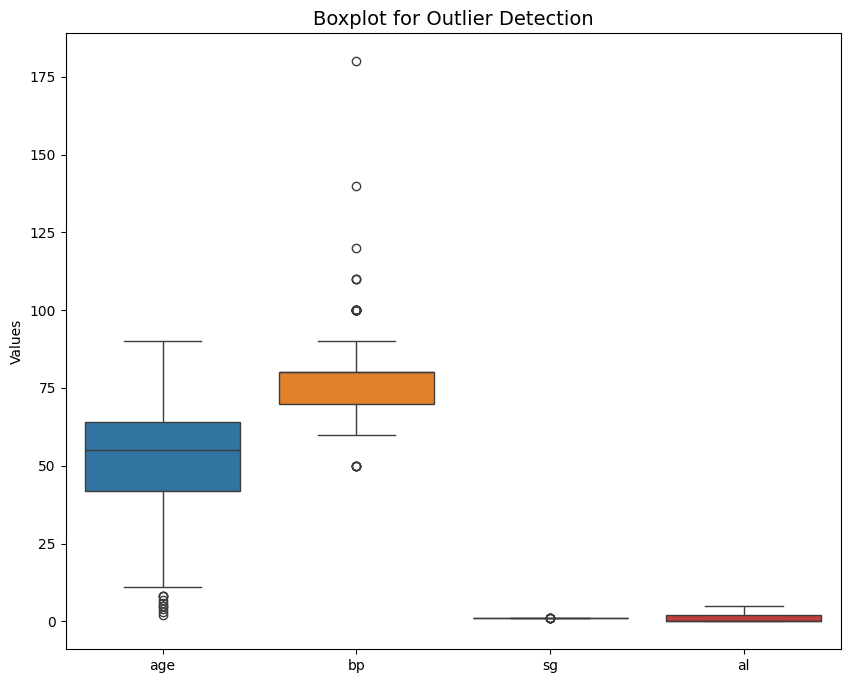

In [36]:
# Data Visualisation before the Outlier Treatment
plt.figure(figsize=(10,8))
sns.boxplot(data=df[['age','bp','sg','al']])
plt.title('Boxplot for Outlier Detection',fontsize=14)
plt.ylabel('Values')
plt.show()

In [37]:
# Treating the outliers
for col in ['age','bp','sg','al']:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3-Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    df[col] = df[col].clip(lower = lower_bound, upper= upper_bound)

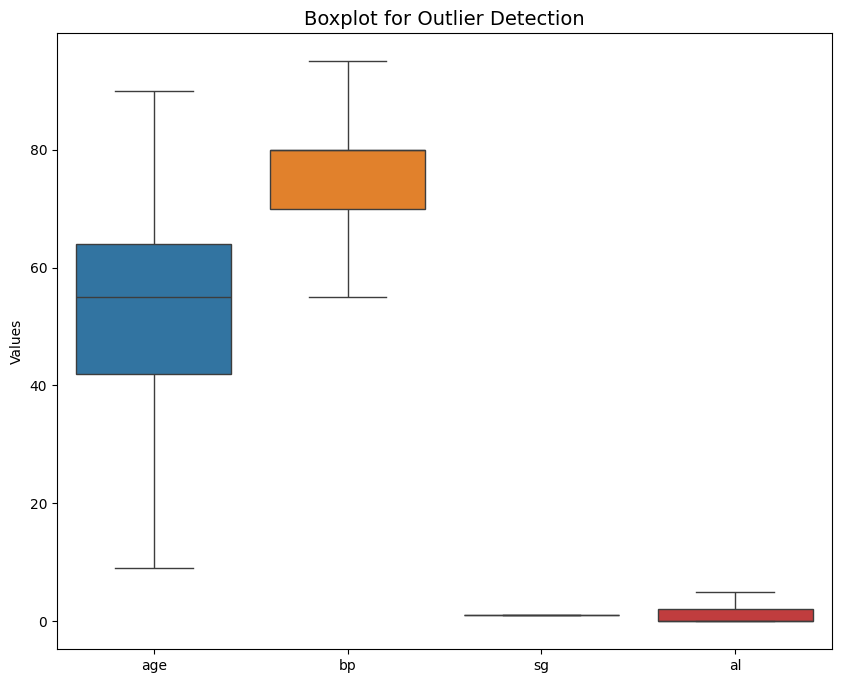

In [38]:
# Data Visualisation after the Outlier Treatment
plt.figure(figsize=(10,8))
sns.boxplot(data=df[['age','bp','sg','al']])
plt.title('Boxplot for Outlier Detection',fontsize=14)
plt.ylabel('Values')
plt.show()

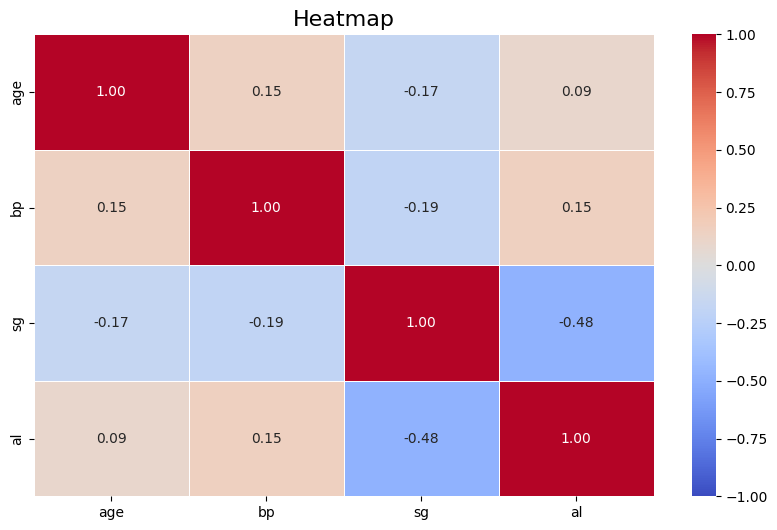

In [39]:
# Correlation
corr_matrix = df[['age','bp','sg','al']].corr()

plt.figure(figsize=(10,6))
sns.heatmap(corr_matrix,
            annot=True,
            cmap='coolwarm',
            fmt=".2f",
            linewidths=0.5,
            vmin=-1, vmax=1)
plt.title('Heatmap', fontsize=16)
plt.show()

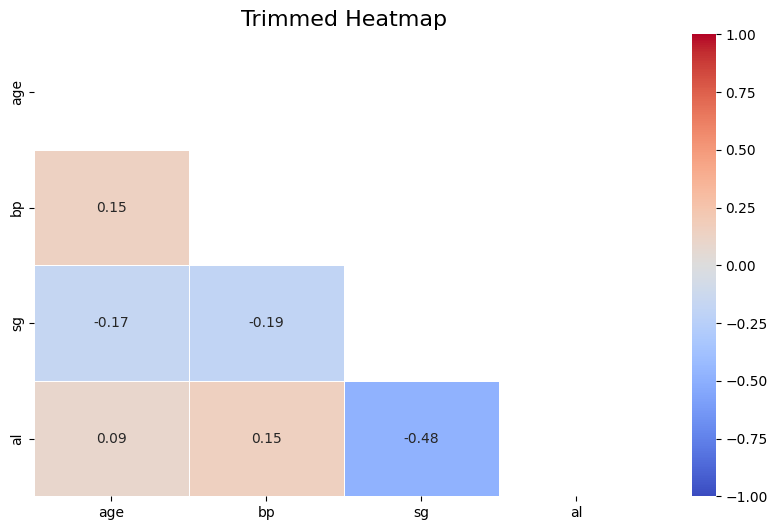

In [42]:
# Correlation
corr_matrix = df[['age','bp','sg','al']].corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
plt.figure(figsize=(10,6))
sns.heatmap(corr_matrix,
            mask=mask,
            annot=True,
            cmap='coolwarm',
            fmt=".2f",
            linewidths=0.5,
            vmin=-1, vmax=1)
plt.title('Trimmed Heatmap', fontsize=16)
plt.show()